# From a BIC to a quasi-BIC: Bar-Dimer Metasurface (Gorkunov *et al.*, Fig. 3a)

> **Reference:** M. V. Gorkunov, A. A. Antonov, and Yu. S. Kivshar, *"Metasurfaces with Maximum Chirality Empowered by Bound States in the Continuum"*, **Phys. Rev. Lett. 125**, 093903 (2020). [arXiv:2006.15884](https://arxiv.org/abs/2006.15884)

A **bound state in the continuum (BIC)** is a resonance that lives at a frequency where light can radiate away, yet it does not, because symmetry forbids it from coupling to the outgoing plane waves. A perfect BIC has an infinite quality factor and is invisible in transmission. Breaking the symmetry slightly opens a weak radiation channel and turns it into a **quasi-BIC (q-BIC)**: a very sharp resonance whose linewidth is set by the size of the perturbation.

The metasurface of Gorkunov *et al.* is made of pairs (dimers) of elliptical dielectric bars. In each dimer the bars carry **antiparallel** electric dipoles, $\mathbf{p}_1 = -\mathbf{p}_2$, so their coupling to a normally incident wave, $m \propto \mathbf{p}_1\cdot\mathbf{e} + \mathbf{p}_2\cdot\mathbf{e}$, vanishes: a BIC. Rotating the two bars in opposite directions by an angle $\theta$ gives $|m| \propto 2p\sin\theta$, so the BIC becomes a q-BIC that shows up as a sharp dip in transmission.

### In this tutorial we will:
1. Build the paper's unit cell, a C4-symmetric square lattice of four bar dimers, with the native Netgen template `chiral_qbic_gorkunov_c4_msh_template.py`.
2. Reproduce **Fig. 3a**: the transmittance from 520 to 650 nm for parallel bars ($d=0$, $\theta=0$, a true BIC) and for rotated bars ($d=0$, $\theta=3^\circ$, a q-BIC), sampled with `adaptive.Learner1D` and a curvature loss, in parallel with `loky`.
3. Locate the q-BIC and compute the near-field enhancements $|\mathbf{E}|^2/|E_0|^2$, $|\mathbf{H}|^2/|H_0|^2$ and the optical chirality enhancement $\hat{C}$ at its wavelength.
4. Export the fields to an `xarray.Dataset`.

In [1]:
import os
import asyncio
from functools import partial

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Ellipse
import adaptive
from adaptive.learner.learner1D import curvature_loss_function
import loky

from EMUstack.backend import objects, stack, materials, plotting
from EMUstack.backend.data.meshes import chiral_qbic_gorkunov_c4_msh_template as c4_cell


##################################################################
EMUstack is brought to you by Bjorn Sturmberg, Kokou Dossou, 
Felix Lawrence & Lindsay Botton, with support from CUDOS & ARENA
Starting EMUstack calculation ...
##################################################################



## 1. The Unit Cell

Parameters from the paper (Fig. 2 and text):

| quantity | value |
|---|---|
| square lattice constant $a$ | 480 nm |
| elliptical bars: length $l$, width $w$, height $h$ | 220 nm, 70 nm, 100 nm |
| gap between parallel bars | 15 nm |
| bar refractive index | $n = 4 + i\kappa$, here $\kappa = 0.01$ |
| background (above, between and below the bars) | air, $n = 1$ |

Each unit cell holds **four dimers**, related by 90° rotations about the cell centre. This C4 symmetry makes the transmission at normal incidence independent of the polarization, so one spectrum per structure is enough. The paper draws the cell as a diamond. The template rotates it by 45° so that the cell edges lie along $x$ and $y$, which does not change any spectrum.

The paper's $\theta$ is the rotation of **each** bar, so the angle between the two bars of a dimer is $2\theta$. This is what the template's `theta_deg` means. The out-of-plane offset $d$ is zero in both structures, so each metasurface is a single 100 nm thick layer containing all eight bars.

The mesh is controlled by `lc` (element size in the air, as a fraction of the period) and `lc2` (refinement factor inside the bars). `lc = 0.06` and `lc2 = 4` give elements of about 29 nm in the air and 7 nm inside the bars, fine enough to resolve the near fields at the ends of the bars.

theta = 0 deg: 3426 mesh nodes, 6736 triangles
theta = 3 deg: 3474 mesh nodes, 6816 triangles


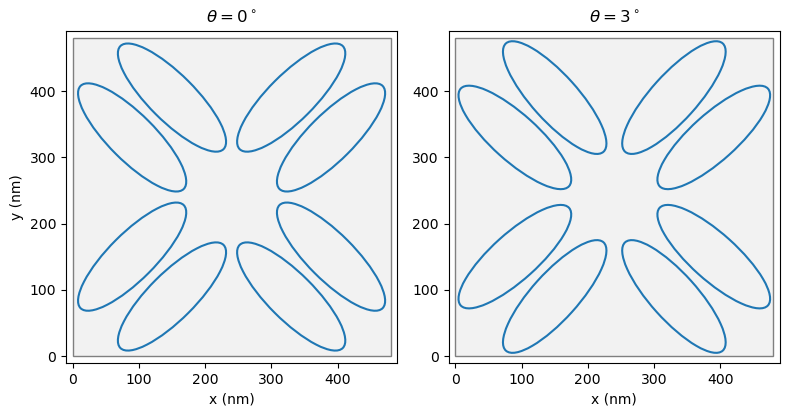

In [2]:
period = 480.0      # nm
height = 100.0      # nm, bar height h (d = 0: one layer)
lc, lc2 = 0.06, 4.0 # mesh: background element size / refinement inside the bars
pw = 7              # plane-wave diffraction orders kept (max_order_PWs)
num_BMs = 500       # Bloch modes kept in the bar layer (see note below)

mat_bars = materials.Material(complex(4.0, 0.01))
mat_air = materials.Material(1.0)

def bar_layer(theta_deg, plotting_fields=0):
    # one 100 nm layer holding the four dimers, with each bar rotated by +/- theta_deg
    return objects.NanoStruct(
        '2D_array', period,
        geo_file='chiral_qbic_gorkunov_c4_msh_template.py',
        geo_params={'period': period, 'theta_deg': theta_deg, 'lc': lc, 'lc2': lc2},
        background=mat_air, inclusion_a=mat_bars, height_nm=height,
        plotting_fields=plotting_fields, plt_msh=False,
    )

thetas = [0.0, 3.0]                       # degrees: true BIC, q-BIC
layers = {th: bar_layer(th) for th in thetas}
air_below = objects.ThinFilm(period=period, height_nm='semi_inf', material=mat_air)
air_above = objects.ThinFilm(period=period, height_nm='semi_inf', material=mat_air)

for th, lay in layers.items():
    print(f"theta = {th:.0f} deg: {lay.n_msh_pts} mesh nodes, {lay.n_msh_el} triangles")

def draw_bars(ax, theta_deg, color='k', **kw):
    # outline the bars from the same inclusion list the template meshes
    for inc in c4_cell.bar_inclusions(period=period, theta_deg=theta_deg):
        (cx, cy), rx, ry = inc['center'], inc['rx'], inc['ry']
        ax.add_patch(Ellipse((cx * period, cy * period), 2 * rx * period, 2 * ry * period,
                             angle=np.rad2deg(inc['angle']), fill=False, ec=color, **kw))

fig, axes = plt.subplots(1, 2, figsize=(8, 4), dpi=100)
for ax, th in zip(axes, thetas):
    ax.add_patch(plt.Rectangle((0, 0), period, period, fc='0.95', ec='0.5'))
    draw_bars(ax, th, color='C0', lw=1.5)
    ax.set_xlim(-10, period + 10); ax.set_ylim(-10, period + 10); ax.set_aspect('equal')
    ax.set_title(rf'$\theta = {th:.0f}^\circ$'); ax.set_xlabel('x (nm)')
axes[0].set_ylabel('y (nm)')
plt.tight_layout()
plt.show()

**Bloch modes.** With eight bars per cell the field inside the layer is rich, and the default number of Bloch modes, $2 N_\mathrm{PW} + 20$, is too small here: with `pw = 3` (78 modes) it underestimates the transmittance near 590 nm by about 0.2. Here we keep 500 modes with `pw = 7`. Too few modes can also break the C4 symmetry of the cell: at `pw = 5`, $T_\mathrm{RCP}$ and $T_\mathrm{LCP}$ differ by 0.02 at the q-BIC with 300 modes, and by less than $10^{-4}$ with 400. The printed $|T_\mathrm{RCP} - T_\mathrm{LCP}|$ below is therefore a useful check of the truncation. The depth of the q-BIC dip converges most slowly; at `pw = 5` the rest of the spectrum changes by about 0.02 between 300 and 400 modes.

With these settings the whole notebook takes about 7.5 hours on 24 cores, most of it for the spectra (about 12 minutes and 5.5 GB of memory per wavelength and worker). For a quick look, `pw = 3`, `num_BMs = 200` and the coarser mesh `lc, lc2 = 0.12, 2.0` run several times faster and already show both resonances, with the q-BIC about 4 nm further from the paper.

## 2. Transmittance Spectra with Adaptive Sampling (Fig. 3a)

The q-BIC is only about a nanometre wide, so a uniform wavelength grid would either miss it or waste most of its points on the smooth parts of the spectrum. `adaptive.Learner1D` with `curvature_loss_function()` instead adds points where the spectrum bends most, and each structure is sampled until its loss drops below **0.02**.

Each point solves the modes of the layer once and then the scattering for both circular polarizations. Since the lattice is C4-symmetric and achiral ($d = 0$), $T_\mathrm{RCP}$ and $T_\mathrm{LCP}$ must coincide, which is a useful check. The two learners share one pool of `loky` worker processes, at most 24, each with a single BLAS/OpenMP thread, so each worker solves one wavelength on its own core.

In [3]:
def spectrum_point(wl, layer):
    # returns (T_RCP, T_LCP, R_RCP, R_LCP) at wavelength wl (nm)
    light = objects.Light(wl, max_order_PWs=pw, theta=0.0, phi=0.0)
    modes = [air_below.calc_modes(light), layer.calc_modes(light, num_BMs=num_BMs),
             air_above.calc_modes(light)]
    out = []
    for pol in ('RCP', 'LCP'):
        stk = stack.Stack(modes)
        stk.calc_scat(pol=pol)
        out.append((float(stk.t_list[-1]), float(stk.r_list[-1])))
    (t_r, r_r), (t_l, r_l) = out
    return (t_r, t_l, r_r, r_l)

wl_range = (520.0, 650.0)   # nm, as in Fig. 3a
n_cpu = os.cpu_count() or 2
n_workers = max(1, min(24, n_cpu - 1))
threads = '1'   # one BLAS/OpenMP thread per worker: one wavelength per core
executor = loky.get_reusable_executor(
    max_workers=n_workers,
    env={'OMP_NUM_THREADS': threads, 'OPENBLAS_NUM_THREADS': threads, 'MKL_NUM_THREADS': threads},
)

learners = {th: adaptive.Learner1D(partial(spectrum_point, layer=layers[th]), bounds=wl_range,
                                   loss_per_interval=curvature_loss_function())
            for th in thetas}
runners = [adaptive.Runner(learner, loss_goal=0.02, executor=executor) for learner in learners.values()]
await asyncio.gather(*(runner.task for runner in runners))

spectra = {}
for th, learner in learners.items():
    wls = np.array(sorted(learner.data))
    vals = np.array([learner.data[w] for w in wls])
    spectra[th] = {'wl': wls, 'T': vals[:, 0], 'T_LCP': vals[:, 1], 'R': vals[:, 2]}
    print(f"theta = {th:.0f} deg: {len(wls)} wavelengths, final loss {learner.loss():.4f}, "
          f"max |T_RCP - T_LCP| = {np.max(np.abs(vals[:, 0] - vals[:, 1])):.1e}")

theta = 0 deg: 52 wavelengths, final loss 0.0182, max |T_RCP - T_LCP| = 5.2e-12
theta = 3 deg: 95 wavelengths, final loss 0.0161, max |T_RCP - T_LCP| = 1.9e-07


### Locating the resonances

The broad dip near 560 nm is the **magnetic-dipole (MD)** resonance of the bars. It is present for both structures. The q-BIC appears only for $\theta = 3^\circ$, as a sharp dip on the long-wavelength side of the MD resonance, where the paper finds it at about 596 nm. We take its wavelength $\lambda_\mathrm{qBIC}$ as the point between 580 and 620 nm where the $\theta = 3^\circ$ spectrum falls furthest below the $\theta = 0$ one. A plain transmittance minimum is not reliable here: the steep flank of the MD resonance near 580 nm can lie lower than the q-BIC dip. Its linewidth (FWHM) is read off the sampled spectrum, measured from the local transmittance maximum just before the dip.

In [4]:
def dip(spec, lo, hi):
    m = (spec['wl'] >= lo) & (spec['wl'] <= hi)
    i = np.flatnonzero(m)[np.argmin(spec['T'][m])]
    return spec['wl'][i], spec['T'][i]

wl_md, t_md = dip(spectra[0.0], 540.0, 580.0)

# q-BIC: where the theta = 3 spectrum falls furthest below the theta = 0 one
s3, s0 = spectra[3.0], spectra[0.0]
m = (s3['wl'] >= 580.0) & (s3['wl'] <= 620.0)
contrast = s3['T'][m] - np.interp(s3['wl'][m], s0['wl'], s0['T'])
i = np.flatnonzero(m)[np.argmin(contrast)]
wl_q, t_q = s3['wl'][i], s3['T'][i]

# q-BIC linewidth: half depth between the dip and the local maximum just before it
win = (s3['wl'] > wl_q - 10.0) & (s3['wl'] < wl_q)
t_top = s3['T'][win].max()
half = 0.5 * (t_top + t_q)
fine = np.linspace(wl_q - 5.0, wl_q + 5.0, 20001)
below = fine[np.interp(fine, s3['wl'], s3['T']) < half]
fwhm = below.max() - below.min()

print(f"MD resonance  (theta = 0): lambda = {wl_md:.1f} nm, T = {t_md:.3f}")
print(f"q-BIC         (theta = 3): lambda = {wl_q:.2f} nm, T = {t_q:.3f}, "
      f"FWHM ~ {fwhm:.2f} nm, Q ~ {wl_q / fwhm:.0f}")
t0_at_q = np.interp(wl_q, spectra[0.0]['wl'], spectra[0.0]['T'])
print(f"theta = 0 at the same wavelength: T = {t0_at_q:.3f} (no resonance: the BIC is dark)")

MD resonance  (theta = 0): lambda = 561.0 nm, T = 0.002
q-BIC         (theta = 3): lambda = 594.54 nm, T = 0.458, FWHM ~ 1.32 nm, Q ~ 450
theta = 0 at the same wavelength: T = 0.887 (no resonance: the BIC is dark)


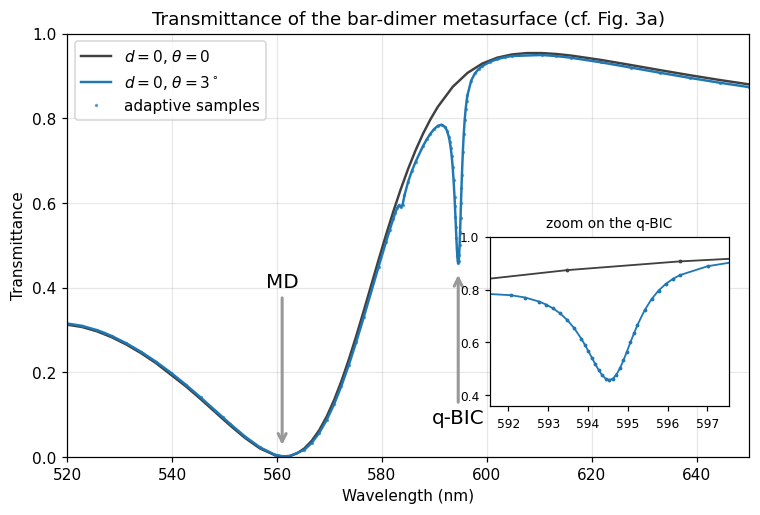

In [5]:
fig, ax = plt.subplots(figsize=(8, 5), dpi=110)
ax.plot(spectra[0.0]['wl'], spectra[0.0]['T'], color='0.25', lw=1.6, label=r'$d = 0$, $\theta = 0$')
ax.plot(spectra[3.0]['wl'], spectra[3.0]['T'], color='C0', lw=1.6, label=r'$d = 0$, $\theta = 3^\circ$')
ax.plot(spectra[3.0]['wl'], spectra[3.0]['T'], '.', color='C0', ms=2.5, alpha=0.6,
        label='adaptive samples')
ax.annotate('MD', (wl_md, t_md + 0.02), (wl_md, 0.4), ha='center', fontsize=13,
            arrowprops=dict(arrowstyle='->', color='0.6', lw=2))
ax.annotate('q-BIC', (wl_q, t_q - 0.02), (wl_q, 0.08), ha='center', fontsize=13,
            arrowprops=dict(arrowstyle='->', color='0.6', lw=2))
ax.set_xlim(*wl_range); ax.set_ylim(0, 1)
ax.set_xlabel('Wavelength (nm)'); ax.set_ylabel('Transmittance')
ax.set_title('Transmittance of the bar-dimer metasurface (cf. Fig. 3a)')
ax.legend(loc='upper left'); ax.grid(alpha=0.3)

inset = ax.inset_axes([0.62, 0.12, 0.35, 0.4])
for th, color in ((0.0, '0.25'), (3.0, 'C0')):
    inset.plot(spectra[th]['wl'], spectra[th]['T'], '.-', color=color, lw=1.2, ms=3)
inset.set_xlim(wl_q - 3, wl_q + 3); inset.set_ylim(max(0.0, t_q - 0.1), 1.0)
inset.set_title('zoom on the q-BIC', fontsize=9); inset.tick_params(labelsize=8)
plt.show()

Compare with Fig. 3a of the paper. Both curves show the MD dip near 560 nm and a transmittance maximum near 600 nm, and only the rotated bars show the sharp q-BIC dip. For the parallel bars the BIC exists at the same frequency but leaves no trace in the spectrum.

**How close is the match?** The MD dip sits at 561 nm with $T \approx 0$, as in the paper. The q-BIC appears at 594.5 nm with $T \approx 0.46$ (paper: about 596.5 nm and 0.33), about 0.3% short. The q-BIC position is the quantity most sensitive to the truncation. Earlier runs of this notebook with coarser settings give:

| `pw` | `lc`, `lc2` | Bloch modes | $\lambda_\mathrm{qBIC}$ (nm) | $T$ at the dip | $Q$ | max $\lvert\mathbf{E}\rvert^2$ | max $\lvert\mathbf{H}\rvert^2$ | max $\lvert\hat{C}\rvert$ |
|---|---|---|---|---|---|---|---|---|
| 3 | 0.12, 2 | 200 | 590.6 | 0.36 | 480 | 540 | 950 | 23 |
| 5 | 0.12, 2 | 400 | 593.3 | 0.44 | 460 | 525 | 890 | 22 |
| 6 | 0.08, 3 | 400 | 594.2 | 0.46 | 450 | 550 | 785 | 14 |
| **7** | **0.06, 4** | **500** | **594.5** | **0.46** | **450** | **570** | **760** | **16** |

The shifts shrink from step to step, so the last two rows are close to converged: the q-BIC moves by 0.3 nm, $Q$ and the dip depth hardly change, the intensity maxima change by about 3%, and the chirality maximum, a single-point value, by about 15%. The remaining 2 nm offset from the paper may come from its different numerical method (COMSOL) and from the exact bar shape and gap, to which the BIC wavelength is sensitive.

**The small kink near 584 nm** for $\theta = 3^\circ$ is not resolved: it was a clear wiggle with `pw = 3` and is smaller with `pw = 5` to 7, but it survives the finer meshes, and its shape changes with the number of Bloch modes. It is absent for $\theta = 0$ and in the paper, so treat it with caution; it is most likely a truncation artifact.

## 3. Field and Chirality Enhancement at the q-BIC

We now solve again at $\lambda_\mathrm{qBIC}$ with `plotting_fields=1`, which keeps the Bloch-mode fields, and reconstruct $\mathbf{E}$ and $\mathbf{H}$ in the mid-plane of the bars ($z = h/2 = 50$ nm). Fields are normalized to the incident plane wave ($|E_0| = |H_0| = 1$), so
- $|\mathbf{E}|^2/|E_0|^2$ and $|\mathbf{H}|^2/|H_0|^2$ are the **field-intensity enhancements**, and
- $\hat{C} = -\operatorname{Im}(\mathbf{E}^*\cdot\mathbf{H})$ is the **optical chirality enhancement**: the local optical chirality density divided by that of a circularly polarized plane wave. In this convention an incident RCP plane wave has $\hat{C} = +1$ and an LCP one $\hat{C} = -1$.

We illuminate with both circular polarizations. For comparison we also evaluate the parallel-bar structure ($\theta = 0$) at the same wavelength, where the BIC cannot be excited.

In [6]:
light_q = objects.Light(wl_q, max_order_PWs=pw, theta=0.0, phi=0.0)
z_mid = 0.5 * height

grid_n = 500
u = np.linspace(0.0, 1.0, grid_n)        # field interpolators take normalized coordinates
U, V = np.meshgrid(u, u)
X, Y = U * period, V * period

fields = {}
for th in thetas:
    lay = bar_layer(th, plotting_fields=1)
    modes = [air_below.calc_modes(light_q), lay.calc_modes(light_q, num_BMs=num_BMs),
             air_above.calc_modes(light_q)]
    for pol in ('RCP', 'LCP'):
        stk = stack.Stack(modes)
        stk.calc_scat(pol=pol)
        b = plotting.fields_interpolator_in_plane(stk, lay_interest=1, z_value=z_mid, return_H=True)
        fields[th, pol] = {'bundle': b, 'E2': b.AbsE(U, V) ** 2, 'H2': b.AbsH(U, V) ** 2,
                           'C': b.chirality_enhancement(U, V)}

print(f"Enhancements in the plane z = {z_mid:.0f} nm at lambda = {wl_q:.2f} nm")
print(f"{'structure':>15} {'pol':>4} {'max |E|^2':>10} {'max |H|^2':>10} {'max C':>8} {'min C':>8} {'mean C':>8}")
for (th, pol), f in fields.items():
    print(f"{'theta = %.0f deg' % th:>15} {pol:>4} {np.nanmax(f['E2']):10.1f} {np.nanmax(f['H2']):10.1f} "
          f"{np.nanmax(f['C']):8.1f} {np.nanmin(f['C']):8.1f} {np.nanmean(f['C']):8.2f}")


##################################################################
EMUstack is brought to you by Bjorn Sturmberg, Kokou Dossou, 
Felix Lawrence & Lindsay Botton, with support from CUDOS & ARENA
Starting EMUstack calculation ...
##################################################################




##################################################################
EMUstack is brought to you by Bjorn Sturmberg, Kokou Dossou, 
Felix Lawrence & Lindsay Botton, with support from CUDOS & ARENA
Starting EMUstack calculation ...
##################################################################




##################################################################
EMUstack is brought to you by Bjorn Sturmberg, Kokou Dossou, 
Felix Lawrence & Lindsay Botton, with support from CUDOS & ARENA
Starting EMUstack calculation ...
##################################################################




##################################################################
EMUstack is brought to you by Bjorn Sturmberg, Kokou Dossou, 
Felix Lawrence & Lindsay Botton, with support from CUDOS & ARENA
Starting EMUstack calculation ...
##################################################################




##################################################################
EMUstack is brought to you by Bjorn Sturmberg, Kokou Dossou, 
Felix Lawrence & Lindsay Botton, with support from CUDOS & ARENA
Starting EMUstack calculation ...
##################################################################




##################################################################
EMUstack is brought to you by Bjorn Sturmberg, Kokou Dossou, 
Felix Lawrence & Lindsay Botton, with support from CUDOS & ARENA
Starting EMUstack calculation ...
##################################################################



... (11 outputs left out)


##################################################################
EMUstack is brought to you by Bjorn Sturmberg, Kokou Dossou, 
Felix Lawrence & Lindsay Botton, with support from CUDOS & ARENA
Starting EMUstack calculation ...
##################################################################




##################################################################
EMUstack is brought to you by Bjorn Sturmberg, Kokou Dossou, 
Felix Lawrence & Lindsay Botton, with support from CUDOS & ARENA
Starting EMUstack calculation ...
##################################################################




##################################################################
EMUstack is brought to you by Bjorn Sturmberg, Kokou Dossou, 
Felix Lawrence & Lindsay Botton, with support from CUDOS & ARENA
Starting EMUstack calculation ...
##################################################################



Enhancements in the plane z = 50 nm at lambda = 594.54 nm
      structure  pol  max |E|^2  max |H|^2    max C    min C   mean C
  theta = 0 deg  RCP       14.9       86.4      7.9     -0.2     1.32
  theta = 0 deg  LCP       14.9       86.7      0.2     -7.9    -1.32
  theta = 3 deg  RCP      568.4      759.2     16.4    -10.6     0.77
  theta = 3 deg  LCP      568.8      758.7     10.7    -16.0    -0.77


### Maps in the mid-plane of the bars ($\theta = 3^\circ$)

Top row: RCP illumination. Bottom row: LCP illumination. The bar outlines are drawn from the same inclusion list the template meshes. The chirality colour scale is symmetric about zero: red is the handedness of RCP, blue that of LCP.

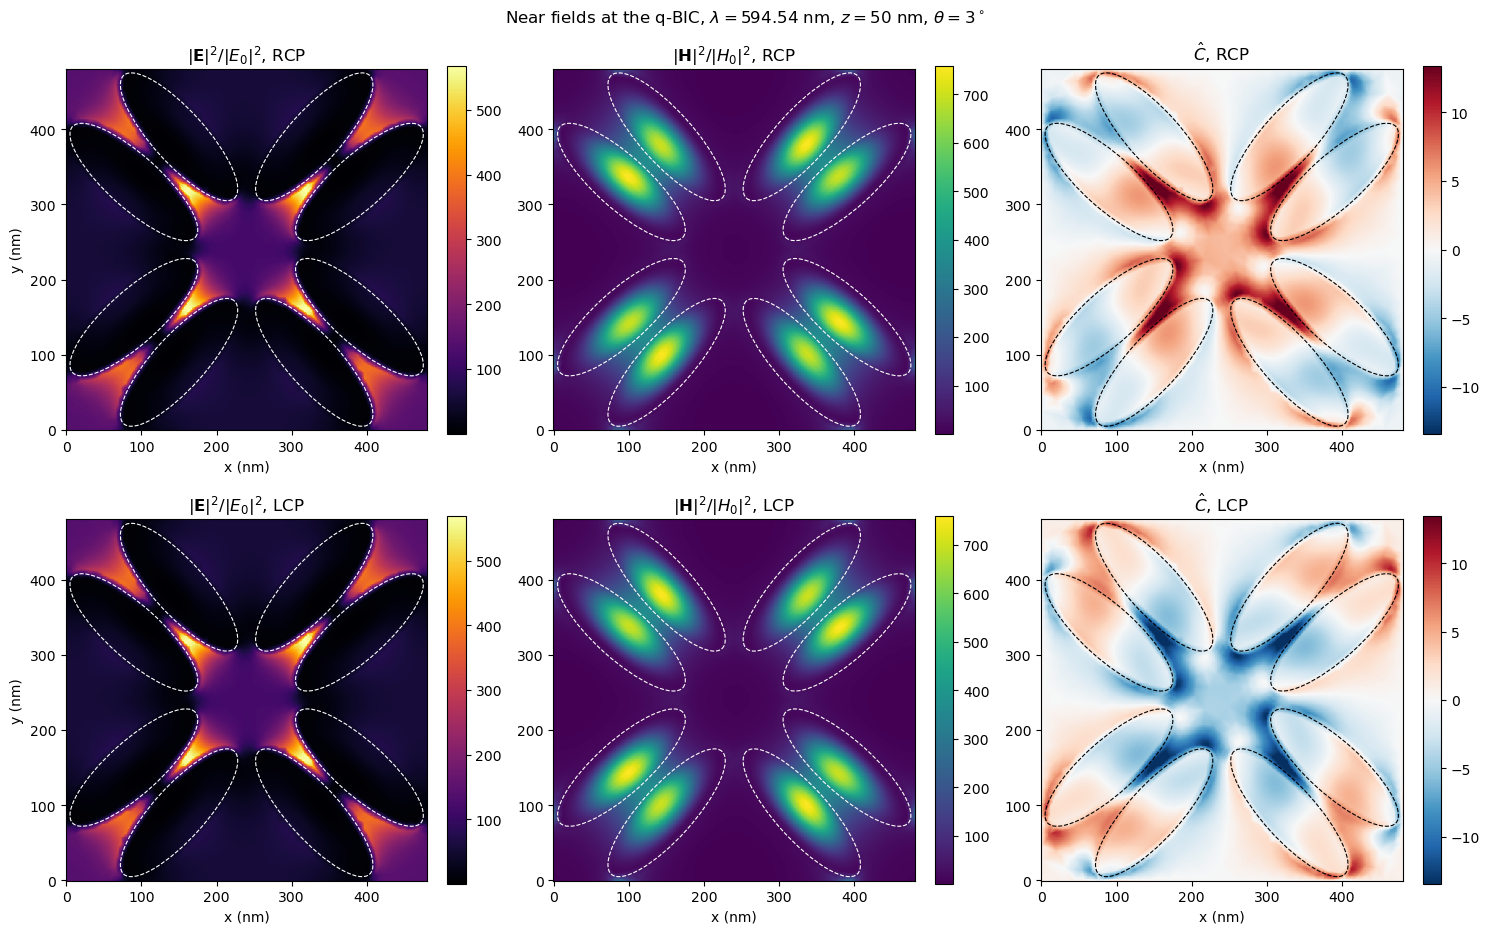

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9.5), dpi=100)
for row, pol in enumerate(('RCP', 'LCP')):
    f = fields[3.0, pol]
    c_lim = float(np.nanpercentile(np.abs(f['C']), 99.5))
    panels = [
        (f['E2'], 'inferno', None, r'$|\mathbf{E}|^2/|E_0|^2$', 'w'),
        (f['H2'], 'viridis', None, r'$|\mathbf{H}|^2/|H_0|^2$', 'w'),
        (f['C'], 'RdBu_r', (-c_lim, c_lim), r'$\hat{C}$', 'k'),
    ]
    for ax, (data, cmap, lims, title, edge) in zip(axes[row], panels):
        vmin, vmax = lims if lims else (None, None)
        im = ax.pcolormesh(X, Y, data, cmap=cmap, vmin=vmin, vmax=vmax, shading='auto')
        draw_bars(ax, 3.0, color=edge, lw=0.8, ls='--')
        ax.set_aspect('equal')
        ax.set_title(f'{title}, {pol}')
        ax.set_xlabel('x (nm)')
        plt.colorbar(im, ax=ax, fraction=0.046)
    axes[row, 0].set_ylabel('y (nm)')
fig.suptitle(rf'Near fields at the q-BIC, $\lambda = {wl_q:.2f}$ nm, $z = {z_mid:.0f}$ nm, $\theta = 3^\circ$')
plt.tight_layout()
plt.show()

## 4. Export the Fields to `xarray`

Each field bundle can be sampled on a grid and packaged into a labelled `xarray.Dataset` (complex field components, intensities and chirality) for later analysis or saving to netCDF.

In [8]:
ds_q = fields[3.0, 'RCP']['bundle'].to_xarray(u, u, dims=('y', 'x'), period=period)
ds_q.attrs.update({'wavelength_nm': float(wl_q), 'theta_deg': 3.0, 'z_nm': z_mid, 'pol': 'RCP'})
ds_q

<xarray.Dataset> Size: 38MB
Dimensions:                (y: 500, x: 500)
Coordinates:
  * y                      (y) float64 4kB 0.0 0.002004 0.004008 ... 0.998 1.0
  * x                      (x) float64 4kB 0.0 0.002004 0.004008 ... 0.998 1.0
Data variables: (12/13)
    Ex                     (y, x) complex128 4MB (0.8051969633151329+8.360973...
    Ey                     (y, x) complex128 4MB (-8.369887991622019+0.813637...
    Ez                     (y, x) complex128 4MB (-2.4279510787112384e-06-5.0...
    AbsE                   (y, x) float64 2MB 11.89 11.88 11.88 ... 11.88 11.89
    Hx                     (y, x) complex128 4MB (0.12663750510425836+1.75306...
    Hy                     (y, x) complex128 4MB (-1.7606521105086732+0.12542...
    ...                     ...
    AbsH                   (y, x) float64 2MB 2.491 2.496 2.503 ... 2.496 2.491
    Sx                     (y, x) float64 2MB -0.007921 0.01413 ... 0.009076
    Sy                     (y, x) float64 2MB 0.004131 0.2386 ... -0.00185
    Sz                     (y, x) float64 2MB -0.3677 -0.3684 ... -0.3688
    chirality_enhancement  (y, x) float64 2MB -0.7355 -0.7368 ... -0.7377
    chirality              (y, x) float64 2MB -1.865 -1.869 ... -1.869 -1.871
Attributes:
    period:         480.0
    wavelength_nm:  594.538043478261
    theta_deg:      3.0
    z_nm:           50.0
    pol:            RCP

## Physical Interpretation

1. **The BIC is dark, the q-BIC is not.** With parallel bars the antiparallel dipoles cancel in the far field, so the mode cannot be excited from normal incidence and the spectrum shows only the broad MD resonance. Rotating the bars by $\pm 3^\circ$ leaves a small net dipole, $|m| \propto 2p\sin\theta$, and the mode appears as a narrow Fano-like dip. Its radiative linewidth scales as $\sin^2\theta$, so smaller angles give even sharper resonances.

2. **High Q means strong near fields.** At the q-BIC ($Q \approx 450$) the incident light is stored in the bars for many optical cycles, which builds up the local fields. In the mid-plane, $|\mathbf{E}|^2$ reaches about 570 times the incident intensity, concentrated at the inner ends of the bars around the cell centre, and $|\mathbf{H}|^2$ about 760 inside the bars, the signature of their magnetic-dipole-like currents. With parallel bars at the same wavelength, where the BIC is not excited, the maxima are only about 15 and 86.

3. **Chirality enhancement without a chiral structure.** For $d = 0$ the metasurface is achiral, so its transmission does not depend on the handedness of the light ($|T_\mathrm{RCP} - T_\mathrm{LCP}| < 10^{-6}$ in the computed spectra), and the LCP chirality map is close to the RCP one with the sign reversed. Circularly polarized light still produces local optical chirality well above that of the incident wave: $|\hat{C}|$ reaches about 16 at the q-BIC, against about 8 for parallel bars, again strongest near the inner ends of the bars. Point maxima like this one depend on the mesh: with the coarser mesh `lc, lc2 = 0.12, 2.0` the maps look grainier and the maximum of $|\hat{C}|$ reads about 22 (see the table above). Both signs appear within the cell, so the cell-averaged enhancement stays small (about 0.8 for RCP). Adding a vertical offset $d \neq 0$ (Fig. 3b of the paper, built with `include_bar1` / `include_bar2` in stacked layers) also breaks the remaining mirror symmetry and makes the q-BIC couple to one circular polarization only, giving maximum chirality.